# Practical 10 - Principal Component Analysis (PCA)
Dataset: Breast Cancer Wisconsin - 569 samples, 30 measurements, 2 classes (benign / malignant)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("breast_cancer.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

cells = pd.read_csv(DATA / "breast_cancer.csv")
features = [c for c in cells.columns if c != "diagnosis"]
COLORS = {"malignant": "#c0392b", "benign": "#2980b9"}

print("Samples :", len(cells), "| Measurements :", len(features))
print("Classes :", cells["diagnosis"].value_counts().to_dict())
print("Missing values:", int(cells.isna().sum().sum()))

Samples : 569 | Measurements : 30
Classes : {'benign': 357, 'malignant': 212}
Missing values: 0


## 1. Basic statistics

In [2]:
overview = cells[features].describe().T[["mean", "std", "min", "max"]]
print(overview.head(10).round(3).to_string())
print("...")
print("Ratio of largest to smallest column mean: %.0f" % (overview["mean"].max() / overview["mean"].min()))

                           mean      std      min       max
mean radius              14.127    3.524    6.981    28.110
mean texture             19.290    4.301    9.710    39.280
mean perimeter           91.969   24.299   43.790   188.500
mean area               654.889  351.914  143.500  2501.000
mean smoothness           0.096    0.014    0.053     0.163
mean compactness          0.104    0.053    0.019     0.345
mean concavity            0.089    0.080    0.000     0.427
mean concave points       0.049    0.039    0.000     0.201
mean symmetry             0.181    0.027    0.106     0.304
mean fractal dimension    0.063    0.007    0.050     0.097
...
Ratio of largest to smallest column mean: 232044


## 2. Box plots by class

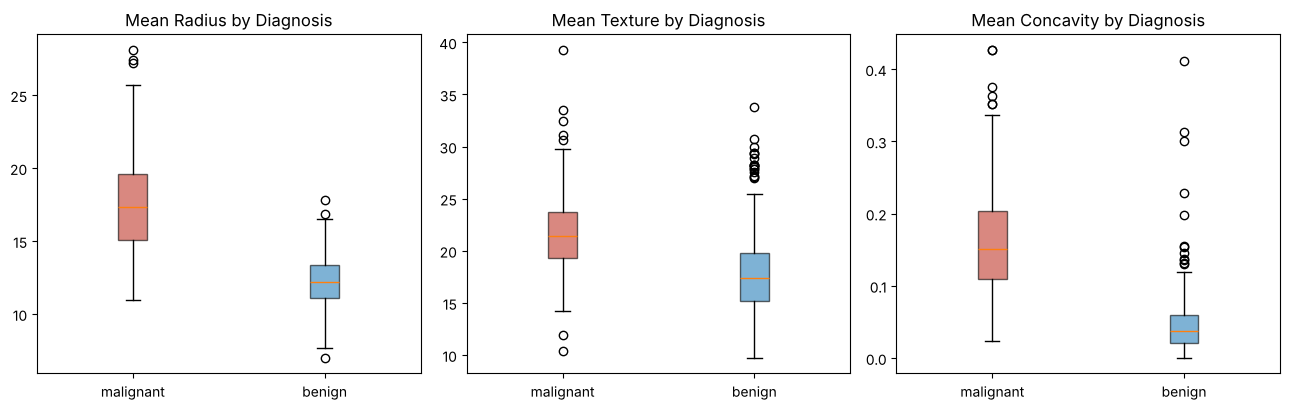

In [3]:
show = ["mean radius", "mean texture", "mean concavity"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, col in zip(axes, show):
    data = [cells.loc[cells["diagnosis"] == d, col] for d in COLORS]
    box = ax.boxplot(data, patch_artist=True, tick_labels=list(COLORS))
    for patch, d in zip(box["boxes"], COLORS):
        patch.set_facecolor(COLORS[d])
        patch.set_alpha(0.6)
    ax.set_title(col.title() + " by Diagnosis")
fig.tight_layout()
fig.savefig(FIG / "boxplots.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Scatter plot of two variables

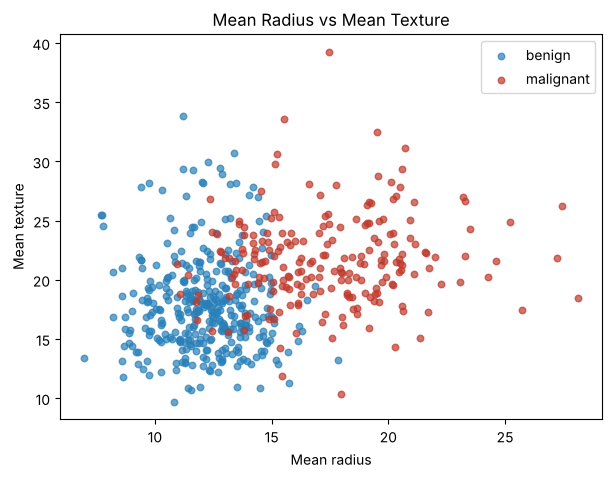

In [4]:
plt.figure(figsize=(7, 5))
for d, part in cells.groupby("diagnosis"):
    plt.scatter(part["mean radius"], part["mean texture"], s=22, alpha=0.7, color=COLORS[d], label=d)
plt.title("Mean Radius vs Mean Texture")
plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.legend()
plt.savefig(FIG / "scatter_two_variables.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Covariance matrix (ten "mean" measurements)

Variance of each measurement (diagonal of the covariance matrix):
mean radius                   12.4189
mean texture                  18.4989
mean perimeter               590.4405
mean area                 123843.5543
mean smoothness                0.0002
mean compactness               0.0028
mean concavity                 0.0064
mean concave points            0.0015
mean symmetry                  0.0008
mean fractal dimension         0.0000


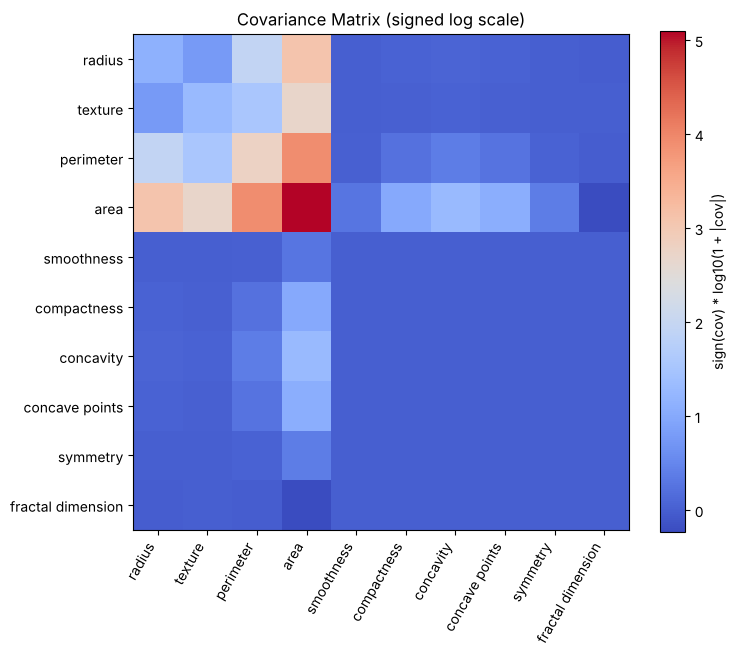

In [5]:
mean_cols = [c for c in features if c.startswith("mean ")]
cov = cells[mean_cols].cov()
print("Variance of each measurement (diagonal of the covariance matrix):")
print(pd.Series(np.diag(cov), index=mean_cols).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.sign(cov) * np.log10(1 + cov.abs()), cmap="coolwarm")
ax.set_xticks(range(len(mean_cols)), [c.replace("mean ", "") for c in mean_cols], rotation=60, ha="right")
ax.set_yticks(range(len(mean_cols)), [c.replace("mean ", "") for c in mean_cols])
ax.set_title("Covariance Matrix (signed log scale)")
fig.colorbar(im, label="sign(cov) * log10(1 + |cov|)")
fig.savefig(FIG / "covariance_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Standardising the data

In [6]:
X = cells[features].to_numpy()
y = cells["diagnosis"].to_numpy()
Z = StandardScaler().fit_transform(X)
print("Mean of scaled columns (first 5):", np.round(Z.mean(axis=0)[:5], 6))
print("Std  of scaled columns (first 5):", np.round(Z.std(axis=0)[:5], 6))

Mean of scaled columns (first 5): [-0.  0. -0. -0. -0.]
Std  of scaled columns (first 5): [1. 1. 1. 1. 1.]


## 6. PCA from first principles (eigen-decomposition)

In [7]:
cov_z = np.cov(Z, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_z)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

ratio = eigvals / eigvals.sum()
print("Largest eigenvalues:", np.round(eigvals[:5], 4))
print("Explained variance ratio of first 5 components:", np.round(ratio[:5], 4))

Largest eigenvalues: [13.305   5.7014  2.8229  1.9841  1.6516]
Explained variance ratio of first 5 components: [0.4427 0.1897 0.0939 0.066  0.055 ]


## 7. PCA with scikit-learn (and a cross-check)

In [8]:
pca = PCA(n_components=2)
scores = pca.fit_transform(Z)

print("Explained variance ratio:")
print(f"  PC1: {pca.explained_variance_ratio_[0]:.2%}")
print(f"  PC2: {pca.explained_variance_ratio_[1]:.2%}")
print(f"  Total (2 components): {pca.explained_variance_ratio_.sum():.2%}")

manual_scores = Z @ eigvecs[:, :2]
same = np.allclose(np.abs(manual_scores), np.abs(scores), atol=1e-6)
print("\nManual eigen-decomposition matches scikit-learn (up to sign):", same)

Explained variance ratio:
  PC1: 44.27%
  PC2: 18.97%
  Total (2 components): 63.24%

Manual eigen-decomposition matches scikit-learn (up to sign): True


      PC1      PC2  diagnosis
0  9.1928   1.9486  malignant
1  2.3878  -3.7682  malignant
2  5.7339  -1.0752  malignant
3  7.1230  10.2756  malignant
4  3.9353  -1.9481  malignant


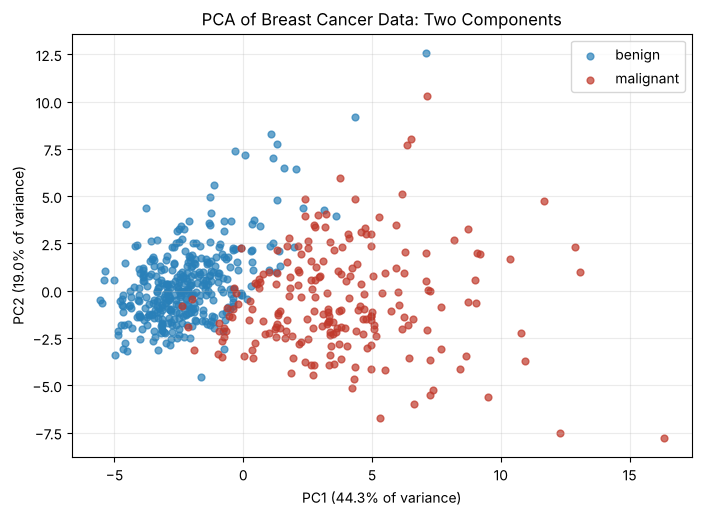

In [9]:
pcs = pd.DataFrame(scores, columns=["PC1", "PC2"]).assign(diagnosis=y)
print(pcs.head().round(4).to_string())

plt.figure(figsize=(8, 5.5))
for d, part in pcs.groupby("diagnosis"):
    plt.scatter(part["PC1"], part["PC2"], s=24, alpha=0.7, color=COLORS[d], label=d)
plt.title("PCA of Breast Cancer Data: Two Components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.legend()
plt.grid(alpha=0.25)
plt.savefig(FIG / "pca_scatter.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. How many components are enough?

Components needed for 80% of the variance: 5
Components needed for 90% of the variance: 7
Components needed for 95% of the variance: 10


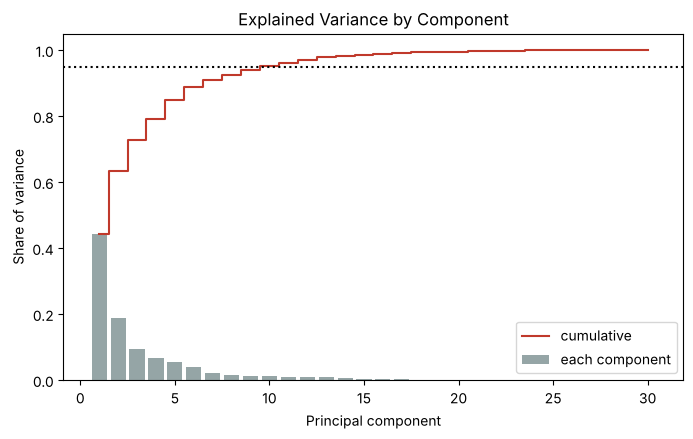

In [10]:
cumulative = np.cumsum(ratio)
for target in (0.80, 0.90, 0.95):
    print(f"Components needed for {target:.0%} of the variance: {int(np.searchsorted(cumulative, target) + 1)}")

plt.figure(figsize=(8, 4.5))
plt.bar(range(1, 31), ratio, color="#95a5a6", label="each component")
plt.step(range(1, 31), cumulative, where="mid", color="#c0392b", label="cumulative")
plt.axhline(0.95, linestyle=":", color="black")
plt.title("Explained Variance by Component")
plt.xlabel("Principal component")
plt.ylabel("Share of variance")
plt.legend()
plt.savefig(FIG / "scree.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
loadings = pd.Series(pca.components_[0], index=features).sort_values(key=np.abs, ascending=False)
print("Features contributing most to PC1:")
print(loadings.head(5).round(4).to_string())

Features contributing most to PC1:
mean concave points     0.2609
mean concavity          0.2584
worst concave points    0.2509
mean compactness        0.2393
worst perimeter         0.2366
